(sec-5-3)=
# 5.3 Convergence and the Gibbs Phenomenon

In the previous two sections we computed Fourier coefficients and then wrote, with some confidence, that the infinite sum of harmonics *equals* the signal. For the smooth ventilator waveform of [Section 5.1](01_fourier_series_derivation.ipynb) that claim is harmless. Physiological signals and the models we build of them are not always smooth, though. A pacemaker stimulus switches on in microseconds, the QRS complex rises by a millivolt in about 20 ms, and the two ends of a finite recording almost never meet at the same value, so its periodic extension has a jump. Whenever such a signal is described by finitely many harmonics, which is what every band-limited amplifier and every low-pass filter effectively does, the reconstruction develops small oscillations next to the steep parts. On an ECG these oscillations can appear in the ST segment, the part of the beat that a cardiologist inspects for signs of ischemia.

This section answers three questions that [Section 5.1](01_fourier_series_derivation.ipynb) left open. In what sense does the series converge, and what does it converge to at a jump? Why does the overshoot next to a jump refuse to shrink, no matter how many harmonics we add? And how fast must the coefficients decay for a waveform to be well described by a few of them? I close with a practical remedy, tapering the coefficients instead of cutting them off, and test it on a real ECG.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy.special import sici

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-5-3-1)=
## 5.3.1 Partial Sums and What "Convergence" Means

A computer can never add infinitely many terms, so the object we actually work with is the **partial sum** that keeps the harmonics up to order $K$:

(eq-5-25)=
\begin{equation*}
x_K(t) = \sum_{n=-K}^{K} c_n\, e^{jn\omega_0 t}, \qquad c_n = \frac{1}{T}\int_T x(\tau)\,e^{-jn\omega_0 \tau}\,d\tau. \tag{5.25}
\end{equation*}

For a real signal this is the same as the trigonometric series [(5.1)](01_fourier_series_derivation.ipynb#eq-5-1) truncated after $K$ harmonics, because the terms $n$ and $-n$ combine into one real cosine. Saying that "the Fourier series converges to $x(t)$" means that $x_K$ approaches $x$ as $K \to \infty$. There are several ways in which one function can approach another, and for Fourier series the difference between them is not academic:

- **Pointwise convergence**: for every fixed instant $t$, the number $x_K(t)$ tends to the number $x(t)$.
- **Uniform convergence**: the worst error over the whole period, $\max_t |x(t) - x_K(t)|$, tends to zero. This is stronger, since it forbids any region where the approximation stays poor.
- **Mean-square convergence**: the average squared error over a period, $\frac{1}{T}\int_T |x(t) - x_K(t)|^2\,dt$, tends to zero. A large error is still allowed, provided it is confined to a region that becomes vanishingly narrow.

We will see that a square wave enjoys pointwise convergence (with a special value at the jumps) and mean-square convergence, but not uniform convergence. The Gibbs phenomenon lives in the gap between these notions.

(sec-5-3-2)=
## 5.3.2 The Dirichlet Kernel and the Midpoint Rule

To understand what the partial sum does to a signal, we substitute the coefficient formula into [(5.25)](#eq-5-25) and rearrange. Peter Gustav Lejeune Dirichlet used exactly this argument in 1829 to give the first rigorous convergence proof.

**Step 1: insert the coefficients.** The sum over $n$ is finite, so we may move it inside the integral:

$$
\begin{aligned}
x_K(t) &= \sum_{n=-K}^{K}\left[\frac{1}{T}\int_T x(\tau)\,e^{-jn\omega_0\tau}\,d\tau\right] e^{jn\omega_0 t} \\
       &= \frac{1}{T}\int_T x(\tau)\left[\sum_{n=-K}^{K} e^{jn\omega_0 (t-\tau)}\right] d\tau .
\end{aligned}
$$

The bracket depends only on the difference $u = t - \tau$. We call it the **Dirichlet kernel** $D_K(u)$, and the partial sum becomes a weighted average of the signal,

(eq-5-26)=
\begin{equation*}
x_K(t) = \frac{1}{T}\int_T x(\tau)\,D_K(t - \tau)\,d\tau, \qquad D_K(u) = \sum_{n=-K}^{K} e^{jn\omega_0 u}. \tag{5.26}
\end{equation*}

This is a periodic convolution: truncating the series is the same as smoothing the signal with the kernel $D_K$.

**Step 2: sum the geometric series.** Write $\theta = \omega_0 u$ and factor out the term with the most negative exponent,

$$
D_K = \sum_{n=-K}^{K} e^{jn\theta} = e^{-jK\theta}\sum_{m=0}^{2K} e^{jm\theta} = e^{-jK\theta}\,\frac{1 - e^{j(2K+1)\theta}}{1 - e^{j\theta}},
$$

which is valid whenever $e^{j\theta} \neq 1$. To simplify the ratio we use the half-angle trick $1 - e^{j\phi} = e^{j\phi/2}\big(e^{-j\phi/2} - e^{j\phi/2}\big) = -2j\,e^{j\phi/2}\sin(\phi/2)$ on the numerator and on the denominator:

$$
\frac{1 - e^{j(2K+1)\theta}}{1 - e^{j\theta}} = \frac{e^{j(2K+1)\theta/2}\,\sin\!\big((2K+1)\theta/2\big)}{e^{j\theta/2}\,\sin(\theta/2)} = e^{jK\theta}\,\frac{\sin\!\big((K+\tfrac12)\theta\big)}{\sin(\theta/2)} .
$$

**Step 3: cancel the phase factors.** The factor $e^{jK\theta}$ cancels the $e^{-jK\theta}$ in front, leaving a real function:

(eq-5-27)=
\begin{equation*}
D_K(u) = \frac{\sin\!\big((K + \tfrac12)\,\omega_0 u\big)}{\sin(\omega_0 u/2)}, \qquad D_K(0) = 2K + 1. \tag{5.27}
\end{equation*}

The value at $u = 0$ follows from the definition directly (all $2K+1$ exponentials equal one) or from the limit $\sin(ax)/\sin(bx) \to a/b$.

Three properties of the kernel explain almost everything that follows. It is even, $D_K(-u) = D_K(u)$. Its average over a period is exactly one, because integrating the sum in [(5.26)](#eq-5-26) term by term kills every exponential except $n = 0$ (the orthogonality relation [(5.17)](02_complex_fourier_series.ipynb#eq-5-17)). And as $K$ grows, its central lobe becomes taller ($2K+1$) and narrower (first zeros at $u = \pm T/(2K+1)$), while the side lobes oscillate faster but do **not** become smaller: away from the origin they are bounded only by $1/|\sin(\omega_0 u/2)|$, which does not depend on $K$. The figure shows the kernel for two values of $K$.

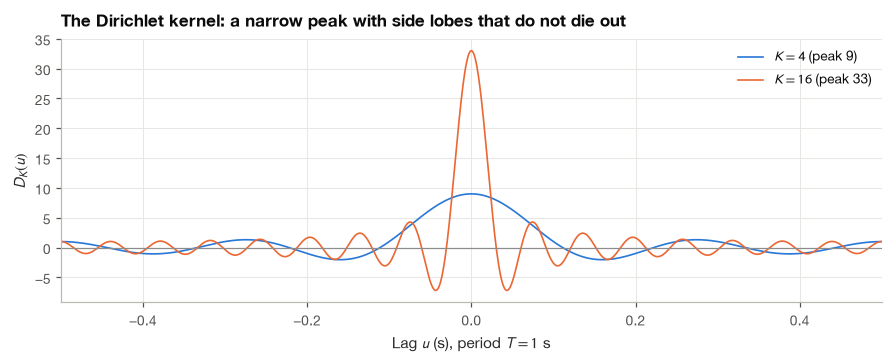

In [2]:
def dirichlet_kernel(u, K, T=1.0):
    """Dirichlet kernel D_K(u) of equation (7.27); u in seconds."""
    w0 = 2 * np.pi / T
    num = np.sin((K + 0.5) * w0 * u)
    den = np.sin(w0 * u / 2)
    out = np.full_like(u, 2 * K + 1, dtype=float)
    ok = np.abs(den) > 1e-12
    out[ok] = num[ok] / den[ok]
    return out


u = np.linspace(-0.5, 0.5, 4001)
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, K in enumerate([4, 16]):
    ax.plot(u, dirichlet_kernel(u, K), color=C[k], lw=1.1, label=f"$K = {K}$ (peak {2 * K + 1})")
ax.axhline(0, color="0.55", lw=0.8)
ax.set(xlabel="Lag $u$ (s), period $T = 1$ s", ylabel="$D_K(u)$",
       title="The Dirichlet kernel: a narrow peak with side lobes that do not die out", xlim=(-0.5, 0.5))
ax.legend(loc="upper right")
plt.show()

### Why the series picks the midpoint at a jump

Suppose $x$ jumps at $t_0$ from the left limit $x(t_0^-)$ to the right limit $x(t_0^+)$. Substituting $\tau = t_0 - u$ in [(5.26)](#eq-5-26) gives $x_K(t_0) = \frac{1}{T}\int_{-T/2}^{T/2} x(t_0 - u)\,D_K(u)\,du$. For $u > 0$ the integrand samples the signal to the *left* of the jump, and for $u < 0$ it samples the right side. Because the kernel is even and averages to one, each half of the integration range carries exactly half of the total weight. As $K$ grows, the kernel oscillates so quickly away from the origin that it averages out any smooth part of the signal there (this is the Riemann–Lebesgue lemma), and only the values of $x$ immediately next to $t_0$ survive. The left half therefore contributes $\tfrac12 x(t_0^-)$, the right half contributes $\tfrac12 x(t_0^+)$, and

(eq-5-28)=
\begin{equation*}
\lim_{K\to\infty} x_K(t_0) = \frac{x(t_0^-) + x(t_0^+)}{2}. \tag{5.28}
\end{equation*}

At a point where the signal is continuous, the two limits coincide and the series converges to $x(t_0)$ itself. The precise statement is known as **Dirichlet's theorem**. If a periodic signal satisfies the **Dirichlet conditions**,

1. it is absolutely integrable over one period, $\int_T |x(t)|\,dt < \infty$,
2. it has a finite number of maxima and minima in one period,
3. it has a finite number of discontinuities in one period, each of them a finite jump,

then its Fourier series converges to $x(t)$ wherever $x$ is continuous and to the midpoint [(5.28)](#eq-5-28) at every jump. The conditions are sufficient, not necessary, and every waveform you will meet in a physiological recording satisfies them. The functions that violate them are mathematical constructions such as $\sin(1/t)$, which has infinitely many extrema near $t = 0$.

We can check [(5.28)](#eq-5-28) on the rectangular pulse train of [Section 5.2.5](02_complex_fourier_series.ipynb#sec-5-2-5), which equals 1 for $|t| < \tau/2$ and 0 elsewhere in the period. Its coefficients $c_n = d\,\operatorname{sinc}(nd)$, with duty cycle $d = \tau/T$, are given by [(5.21)](02_complex_fourier_series.ipynb#eq-5-21). At the edge $t = \tau/2$ the signal jumps from 1 to 0, so the partial sums should approach $0.5$; at the center they should approach $1$.

In [3]:
def partial_sum(c, n, t, T=1.0):
    """Partial Fourier sum (7.25) for coefficients c at harmonic numbers n, evaluated at times t."""
    w0 = 2 * np.pi / T
    return np.real(np.exp(1j * w0 * np.outer(t, n)) @ c)


d = 0.3                                   # duty cycle, T = 1 s
t_test = np.array([0.0, d / 2])           # pulse center and pulse edge
print(" K      x_K(center)   x_K(edge)")
for K in [5, 50, 500, 5000]:
    n = np.arange(-K, K + 1)
    c = d * np.sinc(n * d)                # equation (7.21), np.sinc is sin(pi u)/(pi u)
    center, edge = partial_sum(c, n, t_test)
    print(f"{K:5d}   {center:11.5f}   {edge:9.5f}")

 K      x_K(center)   x_K(edge)
    5       0.96247     0.52250
   50       1.01248     0.49769
  500       0.99875     0.49977
 5000       0.99988     0.49998


The value at the edge settles on $0.5$, halfway between the two levels, while the value at the center approaches $1$. Neither sequence converges monotonically; the center value overshoots and undershoots before it settles, which is a first sign of the oscillations we study in [Section 5.3.4](#sec-5-3-4).

(sec-5-3-3)=
## 5.3.3 Mean-Square Convergence

Pointwise statements tell us what happens at one instant. For signal processing a global measure is usually more useful, and the natural one is the power of the error. Define the **mean-square error** of the partial sum,

$$
E_K = \frac{1}{T}\int_T \big|x(t) - x_K(t)\big|^2\,dt .
$$

The error signal $e_K = x - x_K$ is itself periodic, and its Fourier coefficients are easy to read off: they equal $c_n$ for $|n| > K$ and zero for $|n| \le K$, because $x_K$ contains exactly the low-order harmonics of $x$. Parseval's theorem [(5.19)](02_complex_fourier_series.ipynb#eq-5-19) applied to $e_K$ then gives the error power as a sum of discarded coefficient powers:

(eq-5-29)=
\begin{equation*}
E_K = \sum_{|n| > K} |c_n|^2 . \tag{5.29}
\end{equation*}

The full sum $\sum_n |c_n|^2$ is the power of $x$, which is finite for every physical signal. The tail of a convergent series tends to zero, so **every finite-power periodic signal is the mean-square limit of its Fourier series**. This requirement is much weaker than the Dirichlet conditions, and it is the reason engineers rarely worry about convergence: in the sense of energy, the series always works.

### The truncated series is the best approximation

There is a second reason to like [(5.29)](#eq-5-29). Suppose we approximate $x$ by *any* trigonometric polynomial with $2K+1$ terms, $p(t) = \sum_{|n|\le K} d_n e^{jn\omega_0 t}$, with coefficients $d_n$ of our choosing. The difference $x - p$ has coefficients $c_n - d_n$ for $|n| \le K$ and $c_n$ for $|n| > K$, so by Parseval again,

(eq-5-30)=
\begin{equation*}
\frac{1}{T}\int_T |x(t) - p(t)|^2\,dt = \sum_{|n|\le K} |c_n - d_n|^2 + \sum_{|n|>K} |c_n|^2 \;\ge\; E_K , \tag{5.30}
\end{equation*}

with equality only when $d_n = c_n$ for every $|n| \le K$. Among all sums of $2K+1$ harmonics, the truncated Fourier series has the smallest mean-square error. It is the orthogonal projection of $x$ onto the subspace spanned by the first harmonics, the same projection idea we met in [Section 2.2](../ch02_math_toolkit/03_signals_as_vectors.ipynb). A practical consequence is that adding harmonics never forces us to recompute the ones we already have.

**Example 5.3.1.** For the unit square wave [(5.7)](01_fourier_series_derivation.ipynb#eq-5-7), $b_n = 4/(\pi n)$ for odd $n$, so by [(5.12)](02_complex_fourier_series.ipynb#eq-5-12) $c_n = -jb_n/2 = -2j/(\pi n)$ and $|c_n|^2 = 4/(\pi^2 n^2)$ for odd $n$. Counting both signs of $n$,

$$
E_K = 2\sum_{\substack{n > K \\ n\ \text{odd}}} \frac{4}{\pi^2 n^2} \approx \frac{8}{\pi^2}\int_K^{\infty}\frac{dn}{2n^2} = \frac{4}{\pi^2 K}.
$$

The factor $\tfrac12$ inside the integral accounts for the fact that only every second integer is odd. The square wave has power 1, so the relative error power falls like $0.41/K$: slowly, but steadily, to zero. The next cell compares a direct numerical integration of the error, the tail sum [(5.29)](#eq-5-29) and the approximation $4/(\pi^2 K)$. It also records the largest value of $x_K$, which tells a different story.

In [4]:
T = 1.0
t = np.linspace(-T / 2, T / 2, 200_001)
square = np.sign(np.sin(2 * np.pi * t / T))          # +1 on (0, T/2), -1 on (-T/2, 0)

rows = []
for K in [9, 39, 159, 639]:
    n = np.arange(-K, K + 1)
    c = np.where(n % 2 == 1, -2j / (np.pi * np.where(n == 0, 1, n)), 0)
    xK = partial_sum(c, n, t)
    E_numeric = np.trapezoid((square - xK) ** 2, t) / T
    n_tail = np.arange(K + 1, 400_001)
    E_tail = 2 * np.sum(np.where(n_tail % 2 == 1, 4 / (np.pi ** 2 * n_tail ** 2), 0))
    rows.append({"K": K, "E_K (integral)": E_numeric, "E_K (tail sum)": E_tail,
                 "4/(pi^2 K)": 4 / (np.pi ** 2 * K), "max x_K": xK.max()})
print(pd.DataFrame(rows).set_index("K").to_string(float_format=lambda v: f"{v:.5f}"))

     E_K (integral)  E_K (tail sum)  4/(pi^2 K)  max x_K
K                                                       
9           0.04039         0.04039     0.04503  1.18233
39          0.01013         0.01013     0.01039  1.17919
159         0.00253         0.00253     0.00255  1.17899
639         0.00063         0.00063     0.00063  1.17898


The integral and the tail sum agree, and both shrink roughly in proportion to $1/K$. The last column does not shrink at all. Whatever $K$ we choose, the partial sum climbs to about $1.179$, almost 18% above the level of the square wave. The mean-square error vanishes, but the maximum error does not, so the convergence is not uniform.

(sec-5-3-4)=
## 5.3.4 The Gibbs Phenomenon

The persistent overshoot is called the **Gibbs phenomenon**. Henry Wilbraham described it in 1848, and it became widely known only fifty years later, after an exchange in *Nature* in 1898 and 1899 in which Albert Michelson reported odd peaks in the output of his mechanical harmonic analyzer and Josiah Willard Gibbs explained them {cite:p}`hewitt1979`. We can compute the height of the peak exactly.

Keep $M$ nonzero terms of the square-wave series, which means harmonics up to $K = 2M - 1$:

$$
S_M(t) = \frac{4}{\pi}\sum_{k=1}^{M}\frac{\sin\!\big((2k-1)\omega_0 t\big)}{2k-1}.
$$

**Step 1: differentiate.** Differentiating term by term removes the awkward denominators,

$$
S_M'(t) = \frac{4\omega_0}{\pi}\sum_{k=1}^{M}\cos\!\big((2k-1)\omega_0 t\big).
$$

**Step 2: sum the cosines.** Write $\theta = \omega_0 t$. Multiplying each term by $2\sin\theta$ and using the product-to-sum identity $2\sin\theta\cos\big((2k-1)\theta\big) = \sin(2k\theta) - \sin\big((2k-2)\theta\big)$, the sum telescopes:

$$
2\sin\theta\sum_{k=1}^{M}\cos\big((2k-1)\theta\big) = \sin(2M\theta) - \sin(0) = \sin(2M\theta).
$$

Hence

$$
S_M'(t) = \frac{2\omega_0}{\pi}\,\frac{\sin(2M\omega_0 t)}{\sin(\omega_0 t)}.
$$

**Step 3: locate the first peak.** Just to the right of the jump at $t = 0$, the denominator is positive and the derivative is positive until the numerator first changes sign, at $2M\omega_0 t = \pi$. The first and highest maximum therefore sits at

$$
t_M = \frac{\pi}{2M\omega_0} = \frac{T}{4M}.
$$

As $M$ grows, the peak moves toward the jump.

**Step 4: evaluate the peak as a Riemann sum.** At $t = t_M$ the argument of the $k$-th sine is $u_k = (2k-1)\pi/(2M)$. These are the midpoints of $M$ equal subintervals of $[0, \pi]$, each of width $\Delta u = \pi/M$. Since $\frac{1}{2k-1} = \frac{\pi}{2M u_k} = \frac{\Delta u}{2u_k}$,

$$
S_M(t_M) = \frac{4}{\pi}\sum_{k=1}^{M}\sin(u_k)\,\frac{\Delta u}{2u_k} = \frac{2}{\pi}\sum_{k=1}^{M}\frac{\sin u_k}{u_k}\,\Delta u .
$$

**Step 5: take the limit.** The last sum is a midpoint rule for the integral of $\sin u/u$ over $[0,\pi]$. As $M \to \infty$ it converges to the **sine integral** $\operatorname{Si}(\pi) = \int_0^\pi \frac{\sin u}{u}\,du \approx 1.85194$, so

(eq-5-31)=
\begin{equation*}
\lim_{M\to\infty} S_M(t_M) = \frac{2}{\pi}\operatorname{Si}(\pi) \approx 1.17898 . \tag{5.31}
\end{equation*}

The overshoot above the level 1 is $0.17898$. Expressed as a fraction of the jump, which is 2, it is $8.95\%$. The same fraction appears for every jump in every piecewise-smooth signal: near a discontinuity the signal looks locally like a scaled and shifted square wave, so a jump of size $J$ produces an overshoot of $\big(\operatorname{Si}(\pi)/\pi - \tfrac12\big)J \approx 0.0895\,J$ on each side.

The result reconciles the two kinds of convergence. The overshoot keeps its height but its width is of order $T/(4M)$, so its contribution to the error power shrinks like $1/M$, exactly as Example 5.3.1 found. At any fixed $t \neq 0$, the peak eventually passes by and $S_M(t) \to 1$. The partial sums converge everywhere, yet there is always a point near the jump where they are 9% wrong.

In [5]:
Si_pi = sici(np.pi)[0]
limit = 2 / np.pi * Si_pi
print(f"Si(pi) = {Si_pi:.5f},  (2/pi) Si(pi) = {limit:.5f}")
print(" M     K    peak location (s)   T/(4M)    peak value   midpoint-rule value")
t_fine = np.linspace(1e-6, 0.1, 100_001)
for M in [5, 20, 80, 320]:
    k = np.arange(1, M + 1)
    S = 4 / np.pi * np.sin(2 * np.pi * np.outer(t_fine, 2 * k - 1)) @ (1 / (2 * k - 1))
    uk = (2 * k - 1) * np.pi / (2 * M)
    riemann = 2 / np.pi * np.sum(np.sin(uk) / uk) * np.pi / M
    print(f"{M:3d}  {2 * M - 1:4d}   {t_fine[S.argmax()]:.6f}          {1 / (4 * M):.6f}   "
          f"{S.max():.5f}      {riemann:.5f}")

Si(pi) = 1.85194,  (2/pi) Si(pi) = 1.17898
 M     K    peak location (s)   T/(4M)    peak value   midpoint-rule value
  5     9   0.050000          0.050000   1.18233      1.18233
 20    39   0.012500          0.012500   1.17919      1.17919
 80   159   0.003125          0.003125   1.17899      1.17899


320   639   0.000781          0.000781   1.17898      1.17898


The numerically located peak sits exactly at $T/(4M)$, and its height approaches $1.17898$ from above. Already with five terms the peak is within 0.3% of its limit. The figure makes the shape of the problem clear: the ripple is squeezed toward the jump but keeps its height.

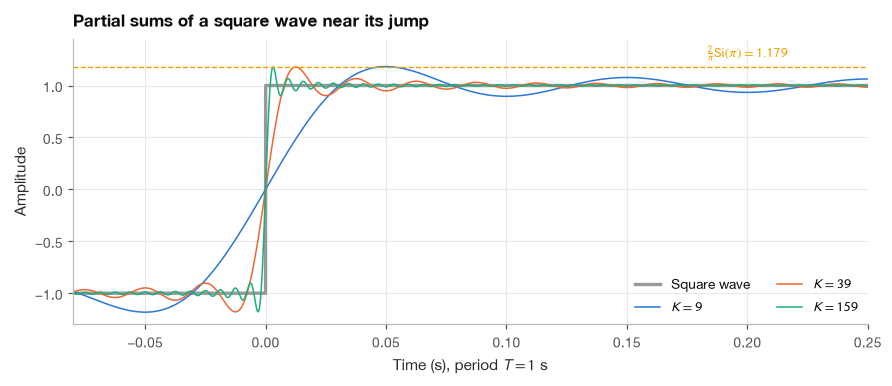

In [6]:
t_zoom = np.linspace(-0.08, 0.25, 6000)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t_zoom, np.sign(t_zoom), color="0.6", lw=2.2, label="Square wave")
for i, M in enumerate([5, 20, 80]):
    k = np.arange(1, M + 1)
    S = 4 / np.pi * np.sin(2 * np.pi * np.outer(t_zoom, 2 * k - 1)) @ (1 / (2 * k - 1))
    ax.plot(t_zoom, S, color=C[i], lw=1.0, label=f"$K = {2 * M - 1}$")
ax.axhline(limit, color=C[3], lw=0.9, ls="--")
ax.annotate(r"$\frac{2}{\pi}\mathrm{Si}(\pi) = 1.179$", (0.2, limit), textcoords="offset points",
            xytext=(0, 6), ha="center", fontsize=9, color=C[3])
ax.set(xlabel="Time (s), period $T = 1$ s", ylabel="Amplitude", ylim=(-1.3, 1.45), xlim=(-0.08, 0.25),
       title="Partial sums of a square wave near its jump")
ax.legend(loc="lower right", ncol=2)
plt.show()

The same ripple explains the "rounded bump" left by the band-limited pacing stimulus in [Section 5.2.7](02_complex_fourier_series.ipynb): a narrow pulse has two jumps close together, and truncating its series leaves Gibbs oscillations on both sides.

(sec-5-3-5)=
## 5.3.5 Smoothness and the Decay of the Coefficients

The square wave needs many harmonics because its coefficients fall off only as $1/n$, while the triangle wave [(5.10)](01_fourier_series_derivation.ipynb#eq-5-10) gets away with fewer because its coefficients fall as $1/n^2$. [Section 5.1](01_fourier_series_derivation.ipynb) promised that this is no coincidence. Integration by parts shows why.

Let $x$ be smooth on each piece of the period, with finite jumps $J_i = x(t_i^+) - x(t_i^-)$ at the instants $t_i$. On each smooth piece we integrate $c_n = \frac{1}{T}\int_T x(t)\,e^{-jn\omega_0 t}\,dt$ by parts, with $x$ as the function to differentiate and $e^{-jn\omega_0 t}$ as the one to integrate (its antiderivative is $e^{-jn\omega_0 t}/(-jn\omega_0)$, for $n \ne 0$):

$$
\int_{t_i}^{t_{i+1}} x(t)\,e^{-jn\omega_0 t}\,dt = \left[\frac{x(t)\,e^{-jn\omega_0 t}}{-jn\omega_0}\right]_{t_i^+}^{t_{i+1}^-} + \frac{1}{jn\omega_0}\int_{t_i}^{t_{i+1}} x'(t)\,e^{-jn\omega_0 t}\,dt .
$$

When we add the pieces of one period, each jump instant $t_i$ appears twice in the boundary terms: once as the upper limit of the piece to its left, with value $x(t_i^-)$ and a minus sign from the antiderivative, and once as the lower limit of the piece to its right, with value $x(t_i^+)$. Together they leave $\big(x(t_i^+) - x(t_i^-)\big)\,e^{-jn\omega_0 t_i}/(jn\omega_0) = J_i\,e^{-jn\omega_0 t_i}/(jn\omega_0)$, and periodicity takes care of the ends of the period. Dividing by $T$ and using $\omega_0 T = 2\pi$,

(eq-5-32)=
\begin{equation*}
c_n = \underbrace{\frac{1}{j2\pi n}\sum_i J_i\,e^{-jn\omega_0 t_i}}_{\text{jumps of } x} \;+\; \frac{1}{jn\omega_0}\,c_n[x'], \qquad n \neq 0, \tag{5.32}
\end{equation*}

where $c_n[x']$ denotes the Fourier coefficients of the derivative. The equation reads like a recipe:

- If $x$ has jumps, the first term has magnitude of order $1/n$ and dominates for large $n$.
- If $x$ is continuous, the first term vanishes and $c_n = c_n[x']/(jn\omega_0)$. Now the jumps of $x'$ (corners of $x$) give $c_n[x'] \sim 1/n$, so $c_n \sim 1/n^2$.
- Repeating the argument: if $x$ and its first $k-1$ derivatives are continuous and the $k$-th derivative has jumps, then $|c_n|$ decays like $1/n^{k+1}$. A signal with infinitely many continuous derivatives has coefficients that decay faster than any power of $n$.

As a check, the unit square wave has $J = +2$ at $t = 0$, $J = -2$ at $t = T/2$, and $x' = 0$ elsewhere. Equation [(5.32)](#eq-5-32) gives $c_n = \frac{2 - 2e^{-jn\pi}}{j2\pi n}$, which is $\frac{4}{j2\pi n} = -\frac{2j}{\pi n}$ for odd $n$ and zero for even $n$, the same result we obtained by integration in Example 5.3.1, but now without computing a single integral.

To see the rule at work we compare four periodic waveforms with increasing smoothness: the square wave (jumps), the triangle wave (corners), a "parabolic" wave $x(t) = t\,(T/2 - |t|)$ on $|t| \le T/2$ (continuous slope, jumps in curvature), and a train of Gaussian pulses with $\sigma = 0.05\,T$ (smooth everywhere). We compute their coefficients with the sampled-period formula [(5.23)](02_complex_fourier_series.ipynb#eq-5-23), using $2^{16}$ samples per period so that aliasing of the coefficients is negligible over the range we plot, and fit the slope of $\log|c_n|$ against $\log n$ over the odd harmonics $11 \le n \le 301$.

In [7]:
N = 2 ** 16
tp = (np.arange(N) - N // 2) / N * T                    # one period, -T/2 <= t < T/2
waves = {
    "square (jumps)": np.sign(np.sin(2 * np.pi * tp)),
    "triangle (corners)": 1 - 4 * np.abs(tp) / T,
    "parabolic (curvature jumps)": tp * (T / 2 - np.abs(tp)),
    "Gaussian train (smooth)": np.exp(-tp ** 2 / (2 * (0.05 * T) ** 2)),
}
n_plot = np.arange(1, 400)
coeffs = {}
for name, x in waves.items():
    ck = np.fft.fft(np.fft.ifftshift(x)) / N              # equation (7.23), t = 0 at index 0
    coeffs[name] = np.abs(ck[n_plot])

fit = (n_plot >= 11) & (n_plot <= 301) & (n_plot % 2 == 1)
for name in list(waves)[:3]:
    mag = coeffs[name]
    slope = np.polyfit(np.log(n_plot[fit]), np.log(mag[fit]), 1)[0]
    print(f"{name:28s} log-log slope = {slope:6.2f}")

sigma = 0.05 * T
for n_check in [1, 11, 21]:
    closed = sigma * np.sqrt(2 * np.pi) / T * np.exp(-2 * np.pi ** 2 * sigma ** 2 * n_check ** 2 / T ** 2)
    print(f"Gaussian train, n = {n_check:2d}: |c_n| = {coeffs['Gaussian train (smooth)'][n_check - 1]:.3e}"
          f"   closed form {closed:.3e}")

square (jumps)               log-log slope =  -1.00
triangle (corners)           log-log slope =  -2.00
parabolic (curvature jumps)  log-log slope =  -3.00
Gaussian train, n =  1: |c_n| = 1.193e-01   closed form 1.193e-01
Gaussian train, n = 11: |c_n| = 3.198e-04   closed form 3.198e-04
Gaussian train, n = 21: |c_n| = 4.433e-11   closed form 4.433e-11


The fitted slopes are $-1$, $-2$ and $-3$ for the first three waveforms, as [(5.32)](#eq-5-32) predicts. The Gaussian train follows no power law at all. Its coefficients agree with the closed form $(\sigma\sqrt{2\pi}/T)\,e^{-2\pi^2\sigma^2 n^2/T^2}$, which comes from the Fourier transform of a Gaussian derived in Section 8.2, and they decay like $e^{-n^2}$: from $n = 11$ to $n = 21$ they lose six orders of magnitude, and a few harmonics later they sink below the rounding error of double-precision arithmetic. On log–log axes, power laws are straight lines and the smooth pulse plunges off the chart.

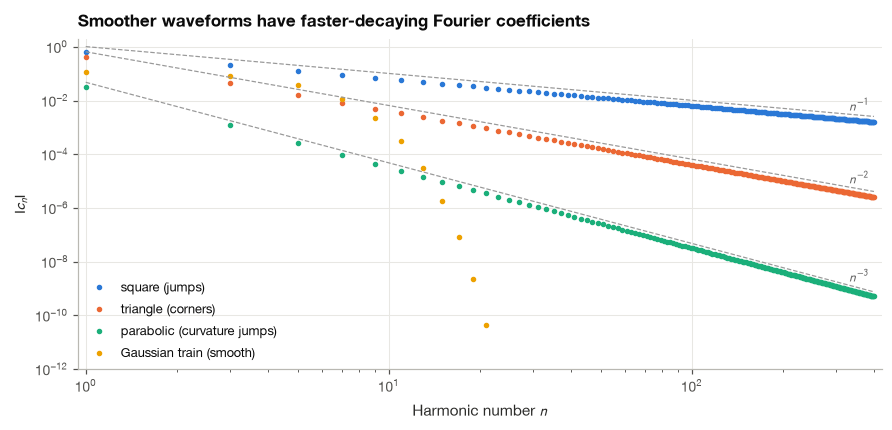

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
odd = n_plot % 2 == 1
for i, (name, mag) in enumerate(coeffs.items()):
    keep = odd & (mag > 1e-15)
    ax.loglog(n_plot[keep], mag[keep], "o", ms=2.6, color=C[i], label=name)
for p, y0 in [(1, 0.64), (2, 0.41), (3, 0.03)]:
    ax.loglog(n_plot, 1.6 * y0 * n_plot.astype(float) ** (-p), color="0.6", lw=0.8, ls="--")
    ax.text(330, 1.6 * y0 * 330.0 ** (-p), f"$n^{{-{p}}}$", fontsize=9, color="0.4", va="bottom")
ax.set(xlabel="Harmonic number $n$", ylabel="$|c_n|$", ylim=(1e-12, 2),
       title="Smoother waveforms have faster-decaying Fourier coefficients")
ax.legend(loc="lower left", fontsize=8.5)
plt.show()

The rule has direct consequences for biomedical signals. A real QRS complex is steep but continuous, so its harmonics decay faster than those of a pulse, and a modest number of them describes it well; Section 7.4 measures how many. A pacing artifact, by contrast, is close to a pair of jumps and spreads its power over hundreds of harmonics. And any finite recording whose last sample differs from its first acquires a jump in its periodic extension, which produces slowly decaying $1/n$ components that have nothing to do with the physiology. This is the origin of the **spectral leakage** that we treat with windows in Section 10.4.

(sec-5-3-6)=
## 5.3.6 Softening the Truncation: Fejér and Lanczos

The Gibbs overshoot comes from the abrupt way we cut the series: harmonics up to $K$ get full weight, and the next one gets none. If we let the weights fall gradually, the oscillations can be tamed. Two classical choices show the idea.

### Fejér means

In 1900 Lipót Fejér proposed averaging the partial sums instead of taking the last one,

$$
\sigma_K(t) = \frac{1}{K+1}\sum_{m=0}^{K} x_m(t).
$$

The harmonic $c_n e^{jn\omega_0 t}$ appears in every partial sum $x_m$ with $m \ge |n|$, which is $K + 1 - |n|$ of the $K+1$ sums. Collecting terms,

(eq-5-33)=
\begin{equation*}
\sigma_K(t) = \sum_{n=-K}^{K}\left(1 - \frac{|n|}{K+1}\right) c_n\,e^{jn\omega_0 t}. \tag{5.33}
\end{equation*}

The weights decrease linearly, a triangular window over the harmonics. The corresponding kernel is the average of the Dirichlet kernels $D_0, \ldots, D_K$. With $\theta = \omega_0 u$, multiplying the numerators $\sin\big((m+\tfrac12)\theta\big)$ by $2\sin(\theta/2)$ turns each into $\cos(m\theta) - \cos\big((m+1)\theta\big)$, and the sum telescopes to $1 - \cos\big((K+1)\theta\big) = 2\sin^2\!\big((K+1)\theta/2\big)$. Hence the **Fejér kernel** is

$$
F_K(u) = \frac{1}{K+1}\sum_{m=0}^{K} D_m(u) = \frac{1}{K+1}\,\frac{\sin^2\!\big((K+1)\,\omega_0 u/2\big)}{\sin^2(\omega_0 u/2)} \;\ge\; 0 .
$$

The kernel is never negative and still averages to one over a period, so $\sigma_K(t)$ is a genuine weighted average of the signal values. A weighted average cannot exceed the largest value being averaged, and therefore **Fejér means never overshoot**. Fejér also proved that $\sigma_K$ converges uniformly to every continuous periodic signal, something the plain partial sums cannot guarantee.

### Lanczos sigma factors

Cornelius Lanczos suggested a different repair {cite:p}`lanczos1956`. The ripple of $x_K$ oscillates at roughly the frequency of the first discarded harmonic, so averaging $x_K$ over one period of that harmonic, a window of length $\Delta = T/(K+1)$, should wash it out. The moving average of a single harmonic is

$$
\frac{1}{\Delta}\int_{t-\Delta/2}^{t+\Delta/2} e^{jn\omega_0 s}\,ds = e^{jn\omega_0 t}\,\frac{e^{jn\omega_0\Delta/2} - e^{-jn\omega_0\Delta/2}}{jn\omega_0\Delta} = e^{jn\omega_0 t}\,\frac{\sin(n\omega_0\Delta/2)}{n\omega_0\Delta/2},
$$

and with $\Delta = T/(K+1)$ the argument is $n\omega_0\Delta/2 = n\pi/(K+1)$. The smoothed sum therefore multiplies each coefficient by a **sigma factor**,

(eq-5-34)=
\begin{equation*}
\tilde{x}_K(t) = \sum_{n=-K}^{K}\operatorname{sinc}\!\left(\frac{n}{K+1}\right) c_n\,e^{jn\omega_0 t}, \qquad \operatorname{sinc}(v) = \frac{\sin(\pi v)}{\pi v}. \tag{5.34}
\end{equation*}

Both remedies are windows applied to the coefficients: a rectangle (plain truncation), a triangle (Fejér) and a sinc main lobe (Lanczos). The next cell applies them to the square wave with $K = 21$ and measures the overshoot as a percentage of the jump and the 10–90% rise time, the time the reconstruction needs to climb from $-0.8$ to $+0.8$.

In [9]:
def rise_time(t, y, lo=-0.8, hi=0.8):
    """10-90% rise time of a reconstruction that steps from -1 to +1 near t = 0."""
    t_hi = t[np.argmax(y >= hi)]
    t_lo = t[(t < t_hi) & (y <= lo)][-1]
    return t_hi - t_lo


K = 21
n = np.arange(-K, K + 1)
c_sq = np.where(n % 2 == 1, -2j / (np.pi * np.where(n == 0, 1, n)), 0)
weights = {"plain truncation": np.ones(n.size),
           "Fejer (7.33)": 1 - np.abs(n) / (K + 1),
           "Lanczos (7.34)": np.sinc(n / (K + 1))}
t_jump = np.linspace(-0.25, 0.25, 20_001)
recon = {name: partial_sum(w * c_sq, n, t_jump) for name, w in weights.items()}
for name, y in recon.items():
    overshoot = max(y.max() - 1, 0) / 2 * 100
    print(f"{name:17s} peak = {y.max():.4f}   overshoot = {overshoot:4.2f} % of the jump   "
          f"rise time = {1e3 * rise_time(t_jump, y):4.1f} ms")

plain truncation  peak = 1.1797   overshoot = 8.98 % of the jump   rise time = 20.3 ms
Fejer (7.33)      peak = 0.9710   overshoot = 0.00 % of the jump   rise time = 48.8 ms
Lanczos (7.34)    peak = 1.0235   overshoot = 1.18 % of the jump   rise time = 37.0 ms


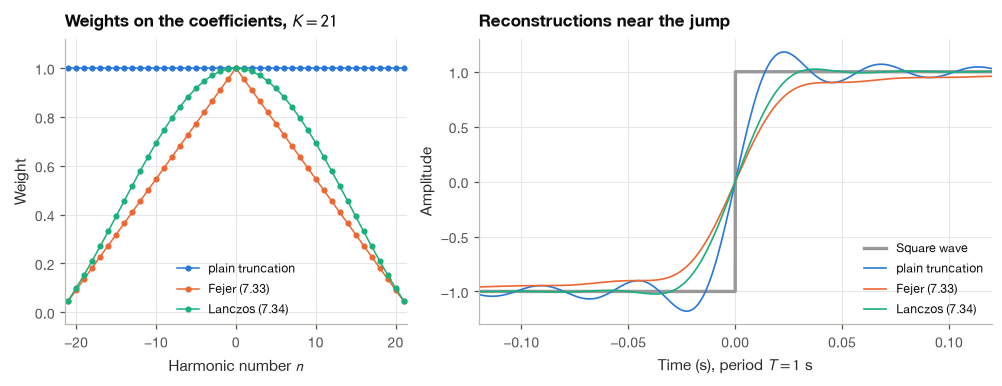

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
for i, (name, w) in enumerate(weights.items()):
    ax.plot(n, w, "o-", ms=3, lw=1, color=C[i], label=name)
ax.set(xlabel="Harmonic number $n$", ylabel="Weight", title=f"Weights on the coefficients, $K = {K}$",
       ylim=(-0.05, 1.12))
ax.legend(loc="lower center", fontsize=8)
ax = axes[1]
ax.plot(t_jump, np.sign(t_jump), color="0.6", lw=2.2, label="Square wave")
for i, (name, y) in enumerate(recon.items()):
    ax.plot(t_jump, y, color=C[i], lw=1.1, label=name)
ax.set(xlabel="Time (s), period $T = 1$ s", ylabel="Amplitude", xlim=(-0.12, 0.12), ylim=(-1.3, 1.3),
       title="Reconstructions near the jump")
ax.legend(loc="lower right", fontsize=8)
plt.show()

The plain partial sum overshoots by about 9% of the jump, as [(5.31)](#eq-5-31) predicts, and rings for several cycles. The Lanczos sum cuts the overshoot to about 1%, and the Fejér sum has no overshoot at all; at $K = 21$ its peak stays below the level of the square wave. Neither repair is free: both edges rise more slowly than the plain sum, and Fejér's is the slowest. Less ringing for a wider transition is a trade-off we will meet again and again, in spectral windows (Section 10.4) and in the window method of FIR filter design (Section 14.2). I find it helpful to remember that the trade-off was first understood here, in the humble problem of summing a square wave.

(sec-5-3-7)=
## 5.3.7 Ringing in a Band-Limited ECG

We now test the theory on a real recording. Imagine an ECG passed through an ideal "brick-wall" low-pass filter, one that keeps every component below a cutoff unchanged and removes everything above it. If we treat a 10-second segment as one period, such a filter is exactly a truncated Fourier series, and the Gibbs analysis applies to every steep part of the waveform. The QRS complex is not a true discontinuity, but at a cutoff of 20 to 40 Hz its upstroke is steep compared with the slowest discarded oscillation, and we should expect ripple next to it.

### Step 1: Load a segment and remove the end-point jump

We read 10 s of lead MLII from MIT-BIH record 100 {cite:p}`moody2001,goldberger2000` together with the beat annotations. The periodic extension of the segment would have a jump wherever the last sample differs from the first, and by [Section 5.3.5](#sec-5-3-5) that jump would ring on its own. We remove it by subtracting the straight line that joins the two end points, a minimal correction that leaves the shape of every beat intact.

In [11]:
fs = 360
seg = slice(0, 10 * fs)
rec = wfdb.rdrecord("../data/mitdb/100", sampfrom=seg.start, sampto=seg.stop, channels=[0])
ann = wfdb.rdann("../data/mitdb/100", "atr", sampfrom=seg.start, sampto=seg.stop)
ecg_raw = rec.p_signal[:, 0]
N = ecg_raw.size
line = ecg_raw[0] + (ecg_raw[-1] - ecg_raw[0]) * np.arange(N) / (N - 1)
ecg = ecg_raw - line
t_ecg = np.arange(N) / fs
r_peaks = ann.sample[np.isin(ann.symbol, ["N"])]
r_peaks = r_peaks[(r_peaks > fs // 2) & (r_peaks < N - fs // 2)]

print(f"Samples: {N},  fundamental of the 10-s period: {fs / N:.2f} Hz")
print(f"End-point mismatch removed: {1e3 * (ecg_raw[-1] - ecg_raw[0]):.0f} uV")
print(f"Normal beats used for measurements: {r_peaks.size}")

Samples: 3600,  fundamental of the 10-s period: 0.10 Hz
End-point mismatch removed: -260 uV
Normal beats used for measurements: 10


### Step 2: Truncate the series at a cutoff, and taper it

With a fundamental of 0.1 Hz, a 25 Hz cutoff keeps the harmonics $|n| \le 250$. We compute all coefficients with the FFT (equation [(5.23)](02_complex_fourier_series.ipynb#eq-5-23) for every $k$ at once, which Chapter 10 explains) and rebuild the signal from the kept ones. For comparison we taper the coefficients with a raised-cosine weight that equals 1 up to 20 Hz, falls smoothly to 0 at 30 Hz and passes through 0.5 at the 25 Hz cutoff. Both versions keep the same amount of the spectrum in the half-amplitude sense; only the abruptness of the edge differs.

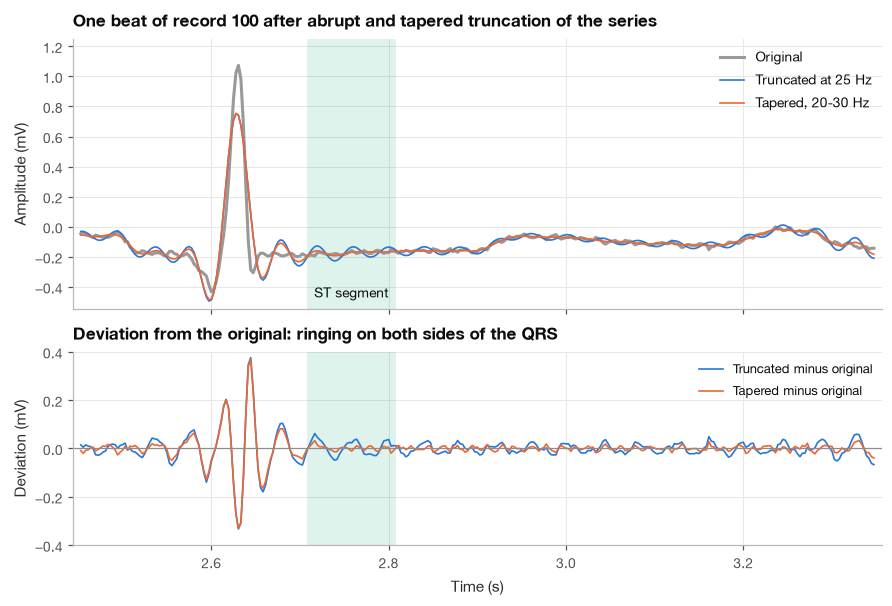

In [12]:
def spectral_lowpass(x, fs, fc, taper_width=0.0):
    """Keep Fourier components below fc; taper_width > 0 uses a raised-cosine edge centered on fc."""
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(x.size, 1 / fs)
    if taper_width == 0:
        weight = (f <= fc).astype(float)
    else:
        edge = np.clip((f - (fc - taper_width / 2)) / taper_width, 0, 1)
        weight = 0.5 * (1 + np.cos(np.pi * edge))
    return np.fft.irfft(X * weight, x.size)


ecg_brick = spectral_lowpass(ecg, fs, 25)
ecg_taper = spectral_lowpass(ecg, fs, 25, taper_width=10)

fig, axes = plt.subplots(2, 1, figsize=(8, 5.4), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
win = (t_ecg > 2.45) & (t_ecg < 3.35)
rp = r_peaks[(r_peaks / fs > 2.45) & (r_peaks / fs < 3.35)][0] / fs
ax = axes[0]
ax.plot(t_ecg[win], ecg[win], color="0.6", lw=2.0, label="Original")
ax.plot(t_ecg[win], ecg_brick[win], color=C[0], lw=1.1, label="Truncated at 25 Hz")
ax.plot(t_ecg[win], ecg_taper[win], color=C[1], lw=1.1, label="Tapered, 20-30 Hz")
ax.set(ylabel="Amplitude (mV)", ylim=(-0.55, 1.25),
       title="One beat of record 100 after abrupt and tapered truncation of the series")
ax.legend(loc="upper right")
ax = axes[1]
ax.plot(t_ecg[win], (ecg_brick - ecg)[win], color=C[0], lw=1.1, label="Truncated minus original")
ax.plot(t_ecg[win], (ecg_taper - ecg)[win], color=C[1], lw=1.1, label="Tapered minus original")
ax.axhline(0, color="0.55", lw=0.8)
ax.set(xlabel="Time (s)", ylabel="Deviation (mV)", ylim=(-0.4, 0.4),
       title="Deviation from the original: ringing on both sides of the QRS")
ax.legend(loc="upper right", fontsize=8.5)
for ax in axes:
    ax.axvspan(rp + 0.08, rp + 0.18, color=C[2], alpha=0.15, lw=0)
axes[0].text(rp + 0.13, -0.47, "ST segment", ha="center", fontsize=9)
plt.show()

The truncated version (blue) oscillates before the Q wave and after the S wave, with a period of about 40 ms, which is one cycle of the 25 Hz cutoff frequency. The ripple appears *before* the QRS as well as after it, because the Dirichlet kernel is symmetric: an ideal truncation is not a causal operation, and it spreads every steep event in both directions of time. The tapered version (orange) loses about the same amount of R-wave height but is visibly calmer in the ST segment, shaded in the figure.

### Step 3: Measure the ringing at several cutoffs

To put numbers on the picture, we measure for every normal beat the mean R-wave amplitude and the peak-to-peak deviation from the original in the ST segment, taken as 80 to 180 ms after the R peak. The original ECG varies slowly there, so any deviation that a low-pass filter introduces in this window is dominated by ringing rather than by the legitimate removal of high-frequency content.

In [13]:
def beat_metrics(y, x, r_peaks, fs):
    """Mean R amplitude (mV) and mean ST-segment peak-to-peak deviation from x (uV)."""
    a, b = int(0.08 * fs), int(0.18 * fs)
    r_amp = np.mean([y[r - 5:r + 6].max() for r in r_peaks])
    st_dev = np.mean([np.ptp(y[r + a:r + b] - x[r + a:r + b]) for r in r_peaks])
    return r_amp, 1e3 * st_dev


rows = []
r_orig, _ = beat_metrics(ecg, ecg, r_peaks, fs)
for fc in [20, 25, 30, 40]:
    rb, sb = beat_metrics(spectral_lowpass(ecg, fs, fc), ecg, r_peaks, fs)
    rt, st = beat_metrics(spectral_lowpass(ecg, fs, fc, taper_width=10), ecg, r_peaks, fs)
    rows.append({"cutoff (Hz)": fc, "R truncated (mV)": rb, "R tapered (mV)": rt,
                 "ST ripple truncated (uV)": sb, "ST ripple tapered (uV)": st})
print(f"Mean R amplitude of the original: {r_orig:.3f} mV")
print(pd.DataFrame(rows).set_index("cutoff (Hz)").round(3).to_string())

Mean R amplitude of the original: 1.172 mV
             R truncated (mV)  R tapered (mV)  ST ripple truncated (uV)  ST ripple tapered (uV)
cutoff (Hz)                                                                                    
20                      0.706           0.698                   127.238                  58.941
25                      0.868           0.860                   107.689                  52.168
30                      0.982           0.979                    83.677                  49.238
40                      1.111           1.110                    51.240                  35.851


At every cutoff the two versions preserve the R wave equally well, to within about 0.01 mV, yet the abrupt truncation leaves between roughly 1.4 and 2.2 times more ST ripple than the tapered one. At 20 and 25 Hz the truncated reconstruction deviates by more than 0.1 mV peak to peak in the ST segment. That is the order of the ST deviations used as diagnostic thresholds for myocardial ischemia (1 mm on standard paper, or 0.1 mV), so a sharp filter of this kind could create or mask a clinically relevant change.

```{important}
A low cutoff alone does not cause ringing; an *abrupt* cutoff does. Real ECG filters are never brick walls, but filters with very steep transitions (high-order elliptic or long FIR designs with a narrow transition band) approach this behavior. When the shape of the ST segment matters, prefer filters with a gentle roll-off, and inspect a few beats in the time domain after filtering. Chapters [14](../ch14_fir/index.md) and 15 return to this compromise.
```

## Summary

The partial sum of a Fourier series is the periodic convolution of the signal with the Dirichlet kernel $D_K(u) = \sin\big((K+\tfrac12)\omega_0 u\big)/\sin(\omega_0 u/2)$. Because this kernel is even and averages to one, the series converges to the signal wherever the signal is continuous and to the midpoint of every jump, provided the Dirichlet conditions hold. In the mean-square sense, convergence holds for every finite-power signal, the error power is the sum of the discarded $|c_n|^2$, and the truncated series is the best possible approximation with that many harmonics. Uniform convergence fails at jumps. The partial sums overshoot by $(\operatorname{Si}(\pi)/\pi - \tfrac12)J \approx 0.0895\,J$ on each side of a jump of size $J$, however many harmonics we keep, while the overshoot region shrinks in width. Integration by parts links smoothness to decay: jumps give coefficients of order $1/n$, corners $1/n^2$, and each further continuous derivative one more power of $n$. Tapering the coefficients (Fejér's triangular weights, Lanczos's sigma factors) trades ringing for a slower transition, and on a real ECG an abrupt 25 Hz truncation leaves roughly twice the ST-segment ripple of a tapered one with the same cutoff.

Section 7.4 uses the decay of the coefficients to ask how many harmonics real ECG and PPG cycles need. The ringing of abrupt truncation returns as the ringing of the ideal low-pass filter in Section 8.2, as spectral leakage in Section 10.4, and as the starting point of window-based filter design in Section 14.2.

## Exercises

1. Show directly from the sawtooth series [(5.8)](01_fourier_series_derivation.ipynb#eq-5-8) that every partial sum equals zero at $t = T/2$, and explain why this agrees with [(5.28)](#eq-5-28). Then use [(5.32)](#eq-5-32) to recover the coefficients $b_n$ of the sawtooth from its single jump and its constant slope, without computing any integral.
2. A half-wave rectified sine, $x(t) = \max\big(\sin(\omega_0 t), 0\big)$, is a crude model of the arterial pulse during systole. Is it continuous? Is its derivative continuous? Predict the decay rate of its coefficients from [(5.32)](#eq-5-32), then verify the prediction numerically with a log–log fit as in [Section 5.3.5](#sec-5-3-5).
3. For the triangle wave [(5.10)](01_fourier_series_derivation.ipynb#eq-5-10), find $|c_n|$, then use [(5.29)](#eq-5-29) and the same integral approximation as in Example 5.3.1 to show that $E_K \approx 16/(3\pi^4 K^3)$. Check the approximation numerically for $K = 9, 39, 159$. Does the triangle wave show a Gibbs overshoot? Why or why not?
4. Complete the derivation of the Fejér kernel: show that $\sum_{m=0}^{K}\sin\big((m+\tfrac12)\theta\big) = \sin^2\big((K+1)\theta/2\big)/\sin(\theta/2)$, verify numerically that $\frac{1}{T}\int_T F_K(u)\,du = 1$, and plot $F_K$ next to $D_K$ for $K = 16$.
5. Repeat the measurements of [Section 5.3.7](#sec-5-3-7) with Lanczos sigma factors [(5.34)](#eq-5-34) in place of the raised-cosine taper, choosing $K$ so that the sigma factor reaches zero at 30 Hz. Compare R amplitude and ST ripple with the two other methods at the same 25 Hz half-amplitude frequency.
6. Load 10 s of MIT-BIH record 119, which contains premature ventricular beats with wide QRS complexes. Apply the 25 Hz truncation of [Section 5.3.7](#sec-5-3-7) and compute the ST ripple separately for normal (`N`) and ventricular (`V`) beats. Which beats ring more, and how does your answer relate to [Section 5.3.5](#sec-5-3-5)?

## Further Reading

{cite:t}`oppenheim1997` (Chapter 3) states the Dirichlet conditions and illustrates the Gibbs phenomenon for the square wave, and {cite:t}`korner1988` gives a rigorous yet readable account of Dirichlet's and Fejér's theorems together with much of their history. The story of Wilbraham, Michelson and Gibbs is told in detail by {cite:t}`hewitt1979`. Lanczos's sigma factors and his view of Fourier series as a practical computing tool appear in {cite:t}`lanczos1956`, and the connection with window design is developed in {cite:t}`harris1978`.